# Five-fold experiments

**Goal:** compare seven understandable techniques, then fit on all training rows.

[All values: CSV](../artifacts/cv_experiments/results.csv) · [Report](../docs/experiment_report.md) · [Q&A](../docs/experiments_qa.html)

This notebook calls reusable classes; it does not implement the training loop. Viewing saved results does not refit models.

In [1]:
import sys
import tomllib
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from notebooks.utils.configuration import resolve_experiments
from notebooks.utils.evaluation import ClassificationEvaluator
from notebooks.utils.experiment import Experiment
from notebooks.utils.features import TfidfFeatures
from notebooks.utils.fitting import CalibratedFit
from notebooks.utils.models import LinearSvmModel
from notebooks.utils.pipeline import TextPipeline
from notebooks.utils.preprocessing import BasicTextPreprocessor
from notebooks.utils.results import ExperimentResults
from notebooks.utils.workflow import ExperimentRunner

config = tomllib.loads((ROOT / "config/experiments.toml").read_text())
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 110)

## Run or inspect

Default: inspect the completed run. To rerun all seven candidates, set the switch to true, or run `uv run python -m notebooks.experiments` from the repository root. Current artifacts are overwritten.

In [2]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    results = ExperimentRunner.from_file(ROOT / "config/experiments.toml").run()
else:
    results = ExperimentResults(ROOT / config["output_dir"])
print("Selected by five-fold macro F1:", results.selected)

Selected by five-fold macro F1: tfidf_svm


## Visible component contracts

```text
BasePreprocessor → BaseFeatureExtractor → BaseMlModel
       BasicTextPreprocessor + TfidfFeatures + LinearSvmModel
       → TextPipeline + CalibratedFit + ClassificationEvaluator
       → Experiment → ExperimentRunner (outer CV/refit/report)
```

Each component below is a concrete object implementing an abstract contract. Native model/vectorizer constructors, parameters, cloning and fitting are preserved. Policies orchestrate whole-pipeline calibration or inner stopping. The TOML registry only resolves names; Python experiments can compose objects directly. Each fit clones the specification, preserving it for later folds.


In [3]:
experiment = Experiment(
    name="visible_tfidf_svm",
    pipeline=TextPipeline(
        preprocessor=BasicTextPreprocessor(lowercase=True),
        features=TfidfFeatures(
            lowercase=False, min_df=2, max_features=5000, sublinear_tf=True
        ),
        model=LinearSvmModel(C=1.0, max_iter=2000, random_state=42),
    ),
    fit_policy=CalibratedFit(folds=5, seed=42, method="temperature"),
    evaluator=ClassificationEvaluator(results.data["labels"]),
)
# The seven configured specifications use the same object composition.
experiments = resolve_experiments(config, results.data["labels"])
experiment.pipeline.build()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,lowercase,True
,lowercase,False
,min_df,2
,max_features,5000
,sublinear_tf,True
,input,'content'
,encoding,'utf-8'


## Seven fixed techniques

Counts versus TF-IDF is compared with the same logistic classifier. Other families have one representative setup. No character fragments, word pairs, or tuning grid.

In [4]:
pd.DataFrame(config["experiments"])

,name,features,model,fit_policy
0,dummy,counts,dummy,standard
1,counts_logistic,counts,logistic_regression,standard
2,tfidf_logistic,tfidf,logistic_regression,standard
3,tfidf_svm,tfidf,svm,calibrated
4,counts_naive_bayes,counts,naive_bayes,standard
5,counts_random_forest,counts,random_forest,standard
6,counts_xgboost,counts,xgboost,early_stopping


## Training, validation and test together

CV cells are mean ± sample standard deviation across five folds. Fractions range 0–1; log loss is lower-is-better. Final training/test each use a single full-data fit: their SD is not estimated. The CSV contains all metrics and individual fold values are in `results.folds()`. Test results did not select the winner.

In [5]:
results.comparison()

candidate       CV train                                \
                   name       accuracy       macro_f1       log_loss   
0             tfidf_svm  0.984 ± 0.001  0.983 ± 0.001  0.066 ± 0.003   
1       counts_logistic  0.976 ± 0.001  0.976 ± 0.001  0.278 ± 0.003   
2        tfidf_logistic  0.928 ± 0.001  0.926 ± 0.001  0.886 ± 0.002   
3        counts_xgboost  0.944 ± 0.002  0.942 ± 0.002  0.351 ± 0.003   
4    counts_naive_bayes  0.884 ± 0.002  0.870 ± 0.003  0.413 ± 0.006   
5  counts_random_forest  0.830 ± 0.007  0.816 ± 0.008  1.932 ± 0.016   
6                 dummy  0.019 ± 0.000  0.000 ± 0.000  4.309 ± 0.000   

   CV validation                               final_train                    \
        accuracy       macro_f1       log_loss    accuracy macro_f1 log_loss   
0  0.883 ± 0.006  0.881 ± 0.005  0.472 ± 0.017       0.981    0.980    0.073   
1  0.866 ± 0.007  0.864 ± 0.007  0.598 ± 0.015       0.975    0.974    0.261   
2  0.860 ± 0.008  0.855 ± 0.007  1.089 ± 0.014       0.928    0.926    0.796   
3  0.838 ± 0.010  0.836 ± 0.010  0.691 ± 0.021       0.941    0.940    0.359   
4  0.806 ± 0.010  0.782 ± 0.009  0.714 ± 0.027       0.886    0.874    0.402   
5  0.765 ± 0.005  0.747 ± 0.004  2.056 ± 0.025       0.832    0.818    1.928   
6  0.019 ± 0.000  0.000 ± 0.000  4.309 ± 0.000       0.019    0.000    4.309   

      test                    
  accuracy macro_f1 log_loss  
0    0.894    0.894    0.422  
1    0.889    0.889    0.518  
2    0.879    0.879    0.959  
3    0.855    0.856    0.620  
4    0.814    0.809    0.716  
5    0.771    0.768    2.060  
6    0.013    0.000    4.384

In [6]:
results.summary()[
    [
        "candidate",
        "cv_validation_roc_auc_macro_mean",
        "test_roc_auc_macro",
        "test_brier",
        "test_coverage",
        "test_accepted_accuracy",
    ]
].round(4)

,candidate,cv_validation_roc_auc_macro_mean,test_roc_auc_macro,test_brier,test_coverage,test_accepted_accuracy
3,tfidf_svm,0.9966,0.9968,0.1549,0.8721,0.9550
1,counts_logistic,0.9968,0.9977,0.1981,0.6705,0.9831
2,tfidf_logistic,0.9960,0.9970,0.3528,0.2844,0.9920
6,counts_xgboost,0.9951,0.9968,0.2267,0.6662,0.9776
4,counts_naive_bayes,0.9942,0.9954,0.2700,0.7185,0.9349
5,counts_random_forest,0.9896,0.9916,0.7202,0.0000,NaN
0,dummy,0.5000,0.5000,0.9878,0.0000,NaN


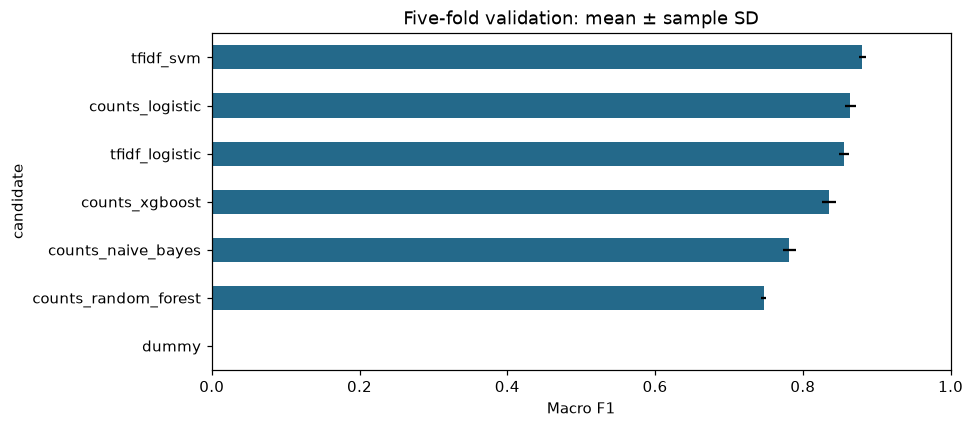

In [7]:
plot = results.summary().sort_values("cv_validation_macro_f1_mean")
ax = plot.plot.barh(
    x="candidate",
    y="cv_validation_macro_f1_mean",
    xerr="cv_validation_macro_f1_std",
    legend=False,
    figsize=(9, 4),
    color="#24698a",
)
ax.set(xlim=(0, 1), xlabel="Macro F1", title="Five-fold validation: mean ± sample SD")
ax.figure.tight_layout()
ax.figure.savefig(ROOT / "docs/images/cv_comparison.png", dpi=140)
ax

## XGBoost learning curve

These are inner fitting/stopping losses for the first outer fold, not the outer validation measurements. Stopping monitored log loss with patience 10. All five fits reached the 80-round cap; this is a budget-limited representative, not an optimized XGBoost result. The selected count is refitted on all outer-training rows. Final boosting uses the median count and all supplied training rows.

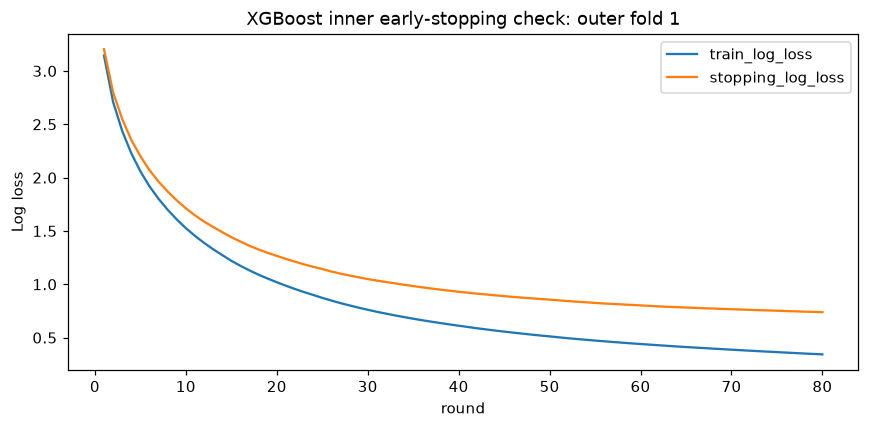

In [8]:
curve = results.learning_curves().query("fold == 0")
ax = curve.plot(x="round", y=["train_log_loss", "stopping_log_loss"], figsize=(8, 4))
ax.set(title="XGBoost inner early-stopping check: outer fold 1", ylabel="Log loss")
ax.figure.tight_layout()
ax.figure.savefig(ROOT / "docs/images/boosting_loss.png", dpi=140)
ax

## Inspect held-out errors

These are out-of-fold predictions: the model did not fit on that row. `results.errors(phase="test")` can inspect confirmation errors, but must not be used to claim a fresh untouched test after further changes.

In [9]:
results.errors(limit=8)

,phase,row_id,text,category,prediction,score,true_probability,correct,action
1675,out_of_fold,1675,Where do I find PIN for my card?,pin_blocked,get_physical_card,0.999896,8.340860e-07,False,route
4792,out_of_fold,4792,There is a payment I don't recognise!,direct_debit_payment_not_recognised,card_payment_not_recognised,0.999888,2.727350e-06,False,route
6798,out_of_fold,6798,Card payment has be declined.,reverted_card_payment?,declined_card_payment,0.999765,3.187470e-06,False,route
3189,out_of_fold,3189,Why didn't my top up work?,top_up_reverted,top_up_failed,0.999529,1.016314e-04,False,route
5623,out_of_fold,5623,Why did my payment get declined?,declined_transfer,declined_card_payment,0.998753,2.385128e-04,False,route
5069,out_of_fold,5069,i entered my pin in wrong and got it frozen. how many tries do i have,declined_cash_withdrawal,pin_blocked,0.998206,4.522549e-04,False,route
225,out_of_fold,225,Can I activate a card in the app?,card_linking,activate_my_card,0.997553,1.874144e-03,False,route
8297,out_of_fold,8297,The amount of cash I requested to withdrawal did not match what I received when exchanged,wrong_exchange_rate_for_cash_withdrawal,wrong_amount_of_cash_received,0.997470,9.864763e-04,False,route


## Try new messages

The score is the highest estimated class probability. The configured threshold is 0.7, with no search. Unknown words are ignored; review is not a reliable unsupported-input detector. No real banking action occurs.

In [10]:
results.predict_examples(
    [
        "Where is my card?",
        "Why do I need to verify my identity?",
        "Where is my crad?",
        "I have a problem.",
        "What is the weather tomorrow?",
    ]
)

,text,prediction,score,action
0,Where is my card?,card_acceptance,0.542339,review
1,Why do I need to verify my identity?,why_verify_identity,0.979071,route
2,Where is my crad?,verify_source_of_funds,0.685623,review
3,I have a problem.,unable_to_verify_identity,0.558352,review
4,What is the weather tomorrow?,cancel_transfer,0.393416,review
